# Stock Triple-Barrier Classification · 02 Triple-Barrier Labeling

# Aim, Objective, and Motivation
- **Aim:** <u>replace</u> "predict tomorrow's price" with a question a trader actually faces:
  *if I buy today, will the trade hit its profit target, its stop-loss, or run out of time first?*
- **Objective:** build triple-barrier labels for every stock and day, verify them, study how the settings change them,
  and handle the fact that neighbouring labels overlap in time.
- **Motivation:** fixed-horizon labels ("is the price higher in 10 days?") ignore the path: a trade that falls 15 % and then
  recovers gets the same label as one that rose steadily. Triple-barrier labels follow the path, like a real stop-loss order.

Method from Marcos López de Prado, *Advances in Financial Machine Learning* (2018), chapters 2–4.

# Outlines
1. Load prices
2. The triple-barrier method
3. Daily volatility: the barrier ruler
4. Three example trades
5. Label every stock
    - 5.1 Brute-force check
    - 5.2 Label distribution
6. Sensitivity to the settings
7. Triple-barrier vs fixed-horizon labels
8. Overlapping labels and sample uniqueness
9. CUSUM filter: sampling events instead of every day
10. Summary

In [1]:
# ---------------------------------------------------------------- Imports
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import TICKERS, VOL_SPAN, PT_MULT, SL_MULT, HORIZON, CLASSES, LABEL_COLORS, PRICE_COLOR
from src.data import download_prices, save_processed
from src.labeling import daily_volatility, triple_barrier, label_all, average_uniqueness, cusum_filter
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
EXAMPLE = "AAPL"
MULT_GRID = [0.5, 0.75, 1.0, 1.5]          # barrier multipliers tested in the sensitivity analysis
HORIZON_GRID = [5, 10, 20]                 # vertical barriers tested (trading days)
N_CHECK = 300                              # random events verified by brute force
CHECK_SEED = 7
CUSUM_VOL_MULT = 1.0                       # CUSUM threshold = this x daily volatility

set_style()

# [1/10] Load prices
> **Objective:** <u>load</u> the cached prices from notebook 01 (the 14 stocks; `SPY` is only used as a feature later).

In [2]:
prices = download_prices()
stocks = prices[prices.ticker.isin(TICKERS)].copy()
close = stocks.pivot(index="date", columns="ticker", values="close")

In [3]:
print(f"{stocks.ticker.nunique()} stocks, {len(stocks):,} stock-days")

14 stocks, 54,012 stock-days


# [2/10] The triple-barrier method
> For an event (a potential trade) starting at day $t_0$ with closing price $P_0$ and daily volatility $\sigma_{t_0}$:
>
> | Barrier | Level | Label if touched first |
> |---|---|---|
> | upper (take-profit) | $P_0 \cdot e^{+m \,\sigma_{t_0} \sqrt{H}}$ | $+1$ |
> | lower (stop-loss) | $P_0 \cdot e^{-m \,\sigma_{t_0} \sqrt{H}}$ | $-1$ |
> | vertical (time limit) | $t_0 + H$ trading days | $0$ |
>
> - $m$ = barrier multiplier (`PT_MULT` = `SL_MULT` = 0.75), $H$ = horizon (`HORIZON` = 10 days).
> - $\sigma\sqrt{H}$ is the typical size of an $H$-day move (volatility grows with the square root of time), so the barriers mean
>   the same thing for a calm stock and a volatile one.
> - The label is known at $t_1$ = the day a barrier is touched (at most $t_0 + H$); $t_1$ matters for splitting and for overlaps.

# [3/10] Daily volatility: the barrier ruler
> **Formula:** exponentially weighted standard deviation of daily log returns,
> $\sigma_t = \sqrt{\text{EWMA}_{\text{span}=20}\left[(r_t - \bar r_t)^2\right]}$ — recent days weigh more, and it uses data up to $t$ only.

In [4]:
vol = close.apply(lambda s: daily_volatility(s.dropna(), VOL_SPAN))
vol_summary = (vol * 100).describe().T[["mean", "min", "50%", "max"]].rename(columns={"50%": "median"})

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
axes[0].plot(close.index, close[EXAMPLE], color=PRICE_COLOR)
axes[0].set(yscale="log", title=f"{EXAMPLE} close (log scale)")
axes[1].plot(vol.index, vol[EXAMPLE] * 100, color="#dc2626")
axes[1].set(ylabel="daily volatility (%)", title=f"{EXAMPLE} EWM daily volatility (span {VOL_SPAN})")
savefig(fig, "02_volatility")
plt.close(fig)

In [5]:
vol_summary.round(2)

,mean,min,median,max
ticker,,,,
AAPL,1.63,0.50,1.49,7.26
ADBE,1.89,0.37,1.71,8.68
AMD,3.33,1.18,3.09,13.67
AMZN,1.93,0.52,1.76,5.23
CRM,2.13,0.52,1.95,7.17
CRWD,3.33,1.51,3.12,9.65
GOOGL,1.63,0.45,1.50,5.93
IBM,1.40,0.44,1.19,9.24
INTC,2.10,0.55,1.74,10.63


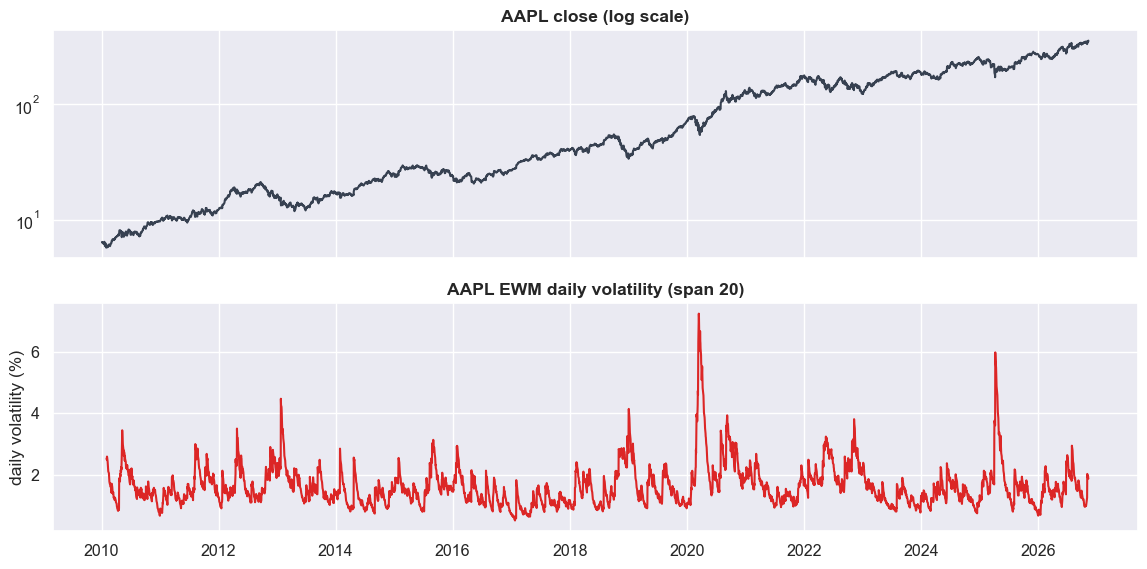

In [6]:
fig

**Answer:** volatility moves a lot over time (spikes in 2020 and during sell-offs) and differs between stocks, so the barrier width
changes with both: wide in turbulent periods, narrow in calm ones.

# [4/10] Three example trades
> **Objective:** <u>see</u> the barriers on real price paths — one example of each label.

In [7]:
c_ex, v_ex = close[EXAMPLE].dropna(), vol[EXAMPLE].dropna()
lab_ex = triple_barrier(c_ex, v_ex.reindex(c_ex.index), HORIZON, PT_MULT, SL_MULT).dropna(subset=["label"])
examples = {k: lab_ex[(lab_ex.label == k) & (lab_ex.index.year == 2023)].index[5] for k in (1, -1, 0)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (k, t0) in zip(axes, examples.items()):
    i = c_ex.index.get_loc(t0)
    window = c_ex.iloc[i - 5: i + HORIZON + 4]
    w = lab_ex.loc[t0, "barrier"]
    p0 = c_ex.iloc[i]
    ax.plot(window.index, window.values, color=PRICE_COLOR, marker="o", ms=3)
    ax.hlines([p0 * np.exp(PT_MULT * w), p0 * np.exp(-SL_MULT * w)], t0, c_ex.index[i + HORIZON],
              colors=[LABEL_COLORS[1], LABEL_COLORS[-1]], lw=2)
    ax.axvline(c_ex.index[i + HORIZON], color="black", ls="--", lw=1)
    ax.axvline(t0, color="black", lw=0.8)
    ax.scatter([lab_ex.loc[t0, "t1"]], [c_ex.loc[lab_ex.loc[t0, "t1"]]], s=120, color=LABEL_COLORS[k], zorder=5)
    ax.set_title(f"{CLASSES[k]} (label {k:+d}) — start {t0.date()}")
    ax.tick_params(axis="x", rotation=30)
savefig(fig, "02_examples")
plt.close(fig)

In [8]:
lab_ex.loc[list(examples.values()), ["label", "ret", "barrier", "t1", "days_held"]].round(4)

,label,ret,barrier,t1,days_held
date,,,,,
2023-01-10,1.0,0.0532,0.0688,2023-01-20,7.0
2023-03-31,-1.0,-0.0295,0.0393,2023-04-12,7.0
2023-02-09,0.0,-0.0264,0.0570,2023-02-24,10.0


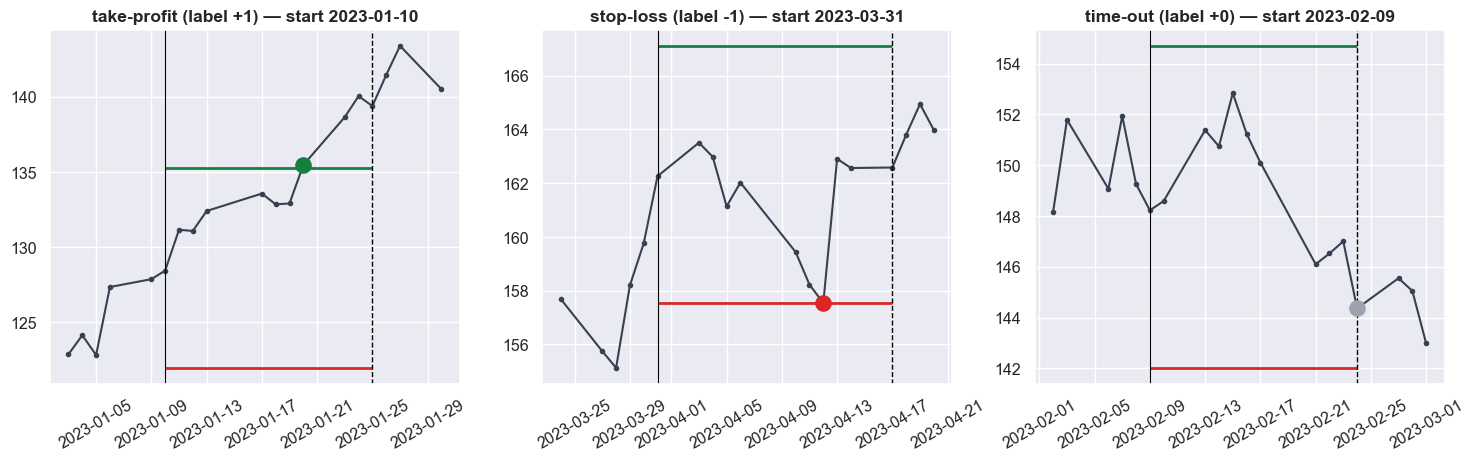

In [9]:
fig

Green and red lines are the take-profit and stop-loss barriers, the dashed line is the vertical barrier, and the large dot marks
where the label was decided ($t_1$).

# [5/10] Label every stock
> **Objective:** <u>label</u> every stock-day (except the last $H$ days of data, whose future is not complete yet).

In [10]:
labels = label_all(stocks, VOL_SPAN, HORIZON, PT_MULT, SL_MULT)

In [11]:
print(f"{len(labels):,} labelled events")
labels.head()

53,592 labelled events


,date,label,ret,barrier,t1,days_held,vol,uniqueness,ticker
0,2010-02-02,0,0.033587,0.080004,2010-02-17,10.0,0.025299,0.292897,AAPL
1,2010-02-03,0,0.018401,0.078785,2010-02-18,10.0,0.024914,0.202897,AAPL
2,2010-02-04,0,0.048877,0.081902,2010-02-19,10.0,0.025900,0.162897,AAPL
3,2010-02-05,0,0.025060,0.081058,2010-02-22,10.0,0.025633,0.139563,AAPL
4,2010-02-08,0,0.015032,0.076708,2010-02-23,10.0,0.024257,0.124563,AAPL


## 5.1 Brute-force check
> **Question:** does the fast labeling code give the same answer as a slow, obviously-correct loop?

In [12]:
rng = np.random.default_rng(CHECK_SEED)
mismatches = 0
for k in rng.choice(len(labels), N_CHECK, replace=False):
    e = labels.iloc[k]
    c = close[e.ticker].dropna()
    i = c.index.get_loc(e.date)
    path = np.log(c.iloc[i + 1: i + 1 + HORIZON] / c.iloc[i])
    hits = [(j, +1) for j, x in enumerate(path) if x >= PT_MULT * e.barrier] + \
           [(j, -1) for j, x in enumerate(path) if x <= -SL_MULT * e.barrier]
    expected = min(hits)[1] if hits else 0
    mismatches += expected != e.label

In [13]:
print(f"{N_CHECK} random events checked -> {mismatches} mismatches")

300 random events checked -> 0 mismatches


## 5.2 Label distribution
> **Question:** how balanced are the three classes, overall and per stock?

In [14]:
overall = labels.label.map(CLASSES).value_counts(normalize=True).mul(100)
per_ticker = pd.crosstab(labels.ticker, labels.label.map(CLASSES), normalize="index").mul(100)
by_year = pd.crosstab(labels.date.dt.year, labels.label.map(CLASSES), normalize="index").mul(100)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
per_ticker[list(CLASSES.values())].plot.barh(stacked=True, ax=axes[0], color=[LABEL_COLORS[k] for k in CLASSES], width=0.8)
axes[0].set(title="Label share per stock (%)", xlabel="%")
axes[0].legend(loc="lower right", fontsize=8)
by_year[list(CLASSES.values())].plot.bar(stacked=True, ax=axes[1], color=[LABEL_COLORS[k] for k in CLASSES], width=0.85)
axes[1].set(title="Label share per year (%)", ylabel="%")
axes[1].legend().remove()
savefig(fig, "02_label_distribution")
plt.close(fig)

In [15]:
overall.round(1)

label
take-profit    36.3
time-out       34.9
stop-loss      28.8
Name: proportion, dtype: float64

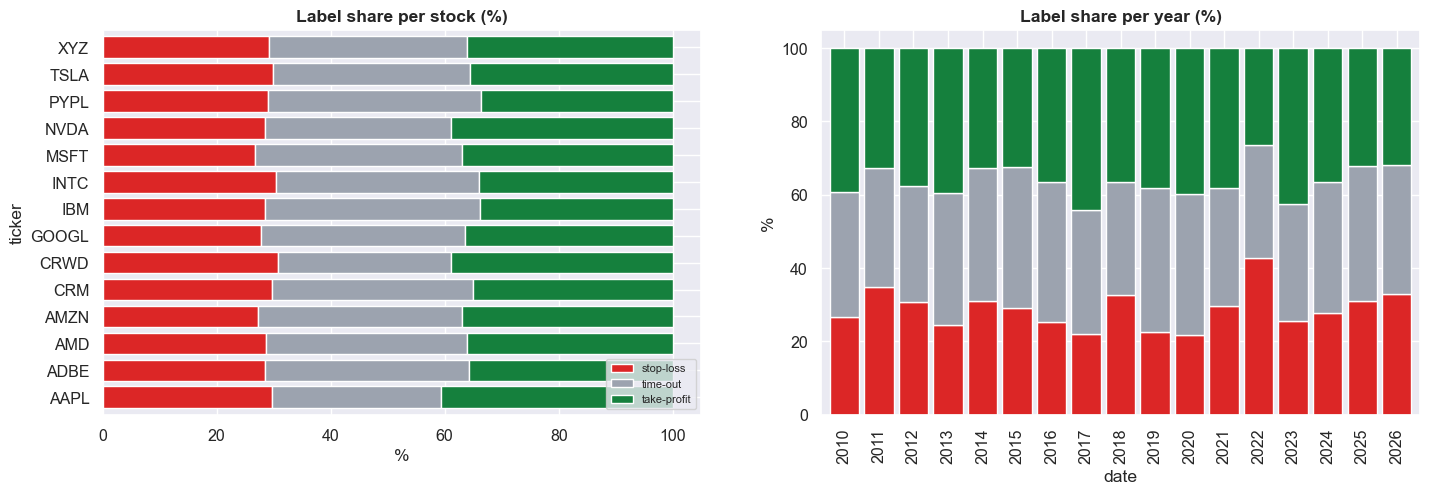

In [16]:
fig

**Answer:** the classes are reasonably balanced overall, so plain accuracy is not misleading here, but macro-F1 and balanced
accuracy are still reported. Take-profit is more common than stop-loss for every one of the 14 stocks, even `INTC` and `PYPL` — they all
went up over the period (selection bias again) — and the mix changes from year to year with the market.

# [6/10] Sensitivity to the settings
> **Question:** how do the barrier multiplier $m$ and the horizon $H$ change the labels?

In [17]:
rows = []
for h in HORIZON_GRID:
    for m in MULT_GRID:
        lab = label_all(stocks, VOL_SPAN, h, m, m)
        share = lab.label.value_counts(normalize=True)
        rows.append({"horizon": h, "mult": m, **{CLASSES[k]: share.get(k, 0) * 100 for k in CLASSES},
                     "mean_days_held": lab.days_held.mean()})
sensitivity = pd.DataFrame(rows)

fig, axes = plt.subplots(1, len(HORIZON_GRID), figsize=(17, 4.2), sharey=True)
for ax, h in zip(axes, HORIZON_GRID):
    s = sensitivity[sensitivity.horizon == h].set_index("mult")[list(CLASSES.values())]
    s.plot.bar(stacked=True, ax=ax, color=[LABEL_COLORS[k] for k in CLASSES], width=0.8, legend=False)
    ax.set(title=f"horizon {h} days", xlabel="barrier multiplier m", ylabel="%")
axes[-1].legend(loc="lower right", fontsize=8)
savefig(fig, "02_sensitivity")
plt.close(fig)

In [18]:
sensitivity.round({"stop-loss": 1, "time-out": 1, "take-profit": 1, "mean_days_held": 1})

,horizon,mult,stop-loss,time-out,take-profit,mean_days_held
0,5,0.50,35.7,20.2,44.1,3.0
1,5,0.75,26.4,41.5,32.1,3.8
2,5,1.00,18.8,58.9,22.3,4.3
3,5,1.50,9.4,80.7,10.0,4.7
4,10,0.50,37.8,14.4,47.7,5.0
5,10,0.75,28.8,34.9,36.3,6.8
6,10,1.00,21.0,53.3,25.7,8.0
7,10,1.50,10.8,77.0,12.2,9.2
8,20,0.50,38.7,10.2,51.1,8.6
9,20,0.75,30.6,29.0,40.4,12.5


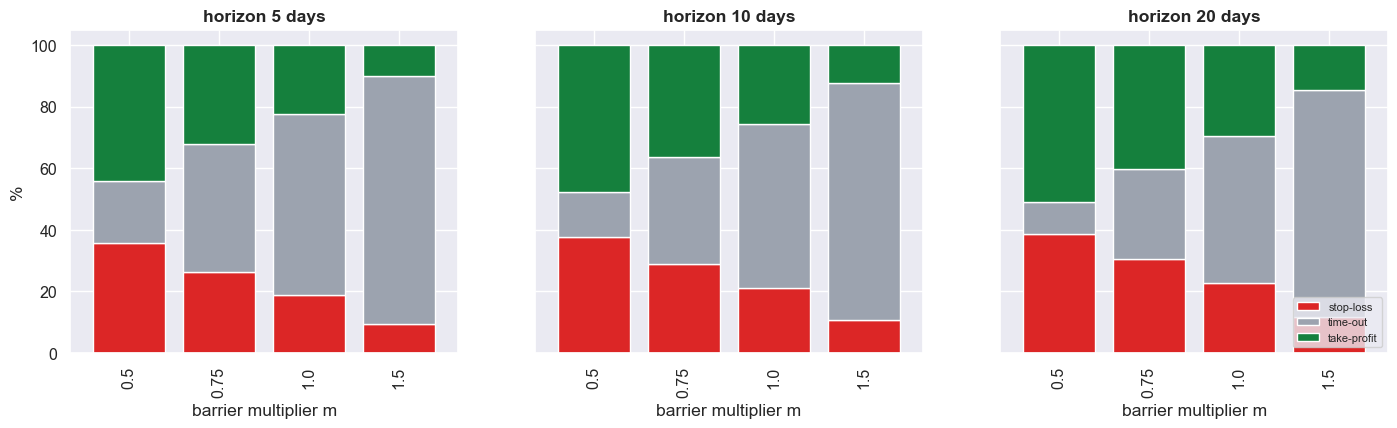

In [19]:
fig

**Answer:** a wider barrier (larger $m$) turns more events into time-outs (from 14 % at $m$ = 0.5 to 77 % at $m$ = 1.5 for $H$ = 10).
Because the width scales with $\sqrt{H}$, the mix changes only moderately with the horizon (longer horizons give slightly fewer
time-outs). $m = 0.75$ with $H = 10$ gives 29 / 35 / 36 % and trades that last about 7 trading days on average — a balanced choice.

# [7/10] Triple-barrier vs fixed-horizon labels
> **Question:** how often does the simple label "price higher after $H$ days" disagree with what a stop-loss would have done?

In [20]:
stocks = stocks.sort_values(["ticker", "date"])
stocks["fixed_sign"] = stocks.groupby("ticker")["close"].transform(lambda c: np.sign(np.log(c.shift(-HORIZON) / c)))
compare = labels.merge(stocks[["date", "ticker", "fixed_sign"]], on=["date", "ticker"])
crosstab = pd.crosstab(compare.label.map(CLASSES), compare.fixed_sign.map({-1: "lower after H", 0: "equal", 1: "higher after H"}),
                       normalize="index").mul(100)
stopped_but_up = ((compare.label == -1) & (compare.fixed_sign == 1)).mean() * 100

In [21]:
print(f"events stopped out first but higher after {HORIZON} days: {stopped_but_up:.1f} % of all events")
crosstab.round(1)

events stopped out first but higher after 10 days: 3.7 % of all events


fixed_sign,equal,higher after H,lower after H
label,,,
stop-loss,0.1,13.0,87.0
take-profit,0.1,91.3,8.7
time-out,0.3,57.4,42.3


**Answer:** 13 % of the stop-loss trades **still** ended higher after 10 days (3.7 % of all events), and 9 % of take-profit trades
ended lower. A fixed-horizon label gets these wrong from a trader's point of view: with a stop-loss, the first group lost money.
Time-outs split 57 / 42 between higher and lower, i.e. a fixed-horizon label turns small, noisy moves into confident up/down labels. Triple-barrier labels describe what actually happens to a trade.

# [8/10] Overlapping labels and sample uniqueness
> **Problem:** an event starting today and one starting tomorrow share up to 9 of the same future days, so their labels are
> **not independent**. Treating them as independent samples overstates how much information we have and inflates cross-validation.
>
> **Formulas** (per stock):
> - concurrency $c_t$ = number of events whose holding period $(t_0, t_1]$ contains day $t$
> - uniqueness of event $i$: $\bar u_i = \frac{1}{|T_i|}\sum_{t \in T_i} \frac{1}{c_t}$ — 1 = no overlap, $\frac{1}{H}$ = completely overlapped
> - used as **sample weights** in training, so overlapping events share their weight instead of counting many times

In [22]:
u_check = average_uniqueness(lab_ex.index, lab_ex["t1"], c_ex.index)
uniq_summary = labels.groupby("ticker").uniqueness.mean().sort_values()
effective_n = labels.uniqueness.sum()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(labels.uniqueness, bins=60, color=PRICE_COLOR, ax=axes[0])
axes[0].set(title="Average uniqueness of events", xlabel="uniqueness")
sns.boxplot(data=labels, x=labels.label.map(CLASSES), y="uniqueness", order=list(CLASSES.values()),
            palette={v: LABEL_COLORS[k] for k, v in CLASSES.items()}, hue=labels.label.map(CLASSES), legend=False, ax=axes[1])
axes[1].set(title="Uniqueness by label", xlabel="")
savefig(fig, "02_uniqueness")
plt.close(fig)

In [23]:
print(f"events: {len(labels):,}  |  effective number of independent events (sum of uniqueness): {effective_n:,.0f}")
labels.groupby(labels.label.map(CLASSES)).uniqueness.mean().round(3)

events: 53,592  |  effective number of independent events (sum of uniqueness): 8,272


label
stop-loss      0.163
take-profit    0.163
time-out       0.138
Name: uniqueness, dtype: float64

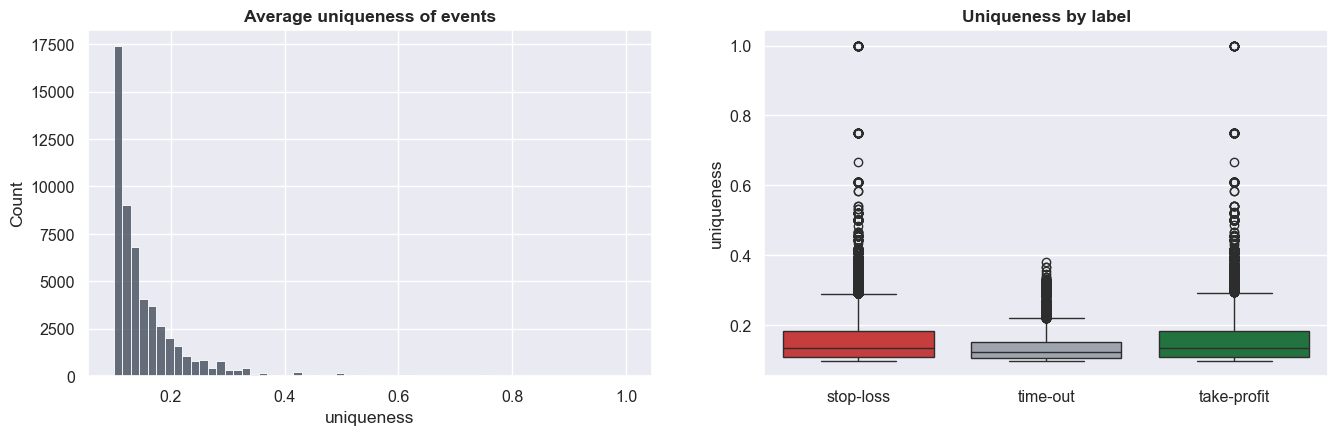

In [24]:
fig

**Answer:** the average event is only about 15 % unique: the 53,592 labelled events hold the information of roughly 8,300
independent trades. Stop-loss and take-profit events end early and overlap less, so they get more weight than
time-outs. → Models are trained with **uniqueness weights**, and validation uses **purging** (notebook 03).

# [9/10] CUSUM filter: sampling events instead of every day
> **Idea:** instead of a trade every day, start an event only after a meaningful move. The symmetric CUSUM filter accumulates
> returns and fires when the sum since the last event passes a threshold $h_t$:
> $S^+_t = \max(0, S^+_{t-1} + r_t)$, $S^-_t = \min(0, S^-_{t-1} + r_t)$; event when $S^+_t > h_t$ or $S^-_t < -h_t$ (then reset),
> with $h_t = \sigma_t$ here.

In [25]:
events = cusum_filter(c_ex, v_ex * CUSUM_VOL_MULT)
cusum_labels = lab_ex.loc[lab_ex.index.intersection(events)]
cusum_compare = pd.DataFrame({
    "every day": lab_ex.label.map(CLASSES).value_counts(normalize=True) * 100,
    "CUSUM events": cusum_labels.label.map(CLASSES).value_counts(normalize=True) * 100,
}).loc[list(CLASSES.values())]
cusum_uniq = average_uniqueness(cusum_labels.index, cusum_labels["t1"], c_ex.index)

window = c_ex.loc["2023-01-01":"2023-06-30"]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(window.index, window.values, color=PRICE_COLOR)
ev = events[(events >= window.index[0]) & (events <= window.index[-1])]
ax.scatter(ev, c_ex.loc[ev], color="#dc2626", s=25, zorder=5, label="CUSUM event")
ax.set(title=f"{EXAMPLE}: CUSUM events, first half of 2023")
ax.legend()
savefig(fig, "02_cusum")
plt.close(fig)

In [26]:
print(f"{EXAMPLE}: {len(lab_ex):,} daily events -> {len(cusum_labels):,} CUSUM events; "
      f"mean uniqueness {lab_ex.index.map(u_check).to_series().mean():.3f} -> {cusum_uniq.mean():.3f}")
cusum_compare.round(1)

AAPL: 4,211 daily events -> 1,672 CUSUM events; mean uniqueness 0.160 -> 0.385


,every day,CUSUM events
label,,
stop-loss,29.7,30.0
time-out,29.5,29.2
take-profit,40.7,40.8


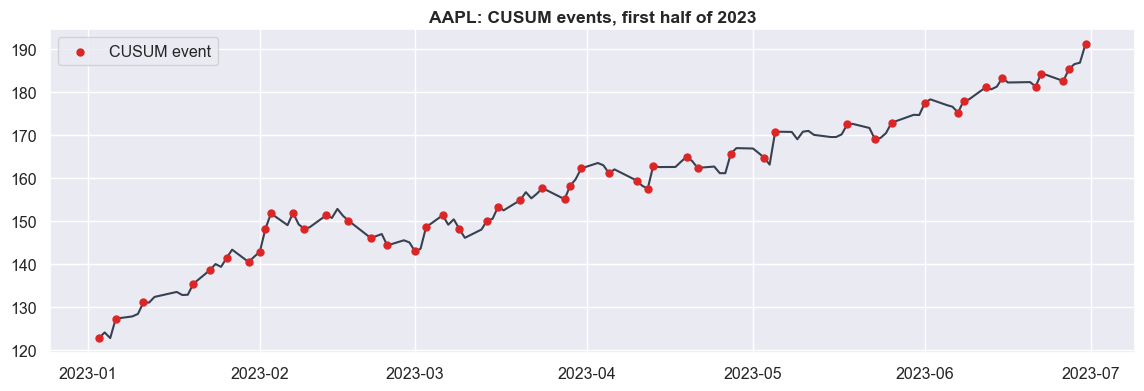

In [27]:
fig

**Answer:** for `AAPL`, CUSUM keeps 1,672 of 4,211 events, raises mean uniqueness from 0.16 to 0.39, and leaves the label mix
almost unchanged. For the deep-learning models this project keeps
**every day** (more training samples) and handles overlap with uniqueness weights instead; CUSUM is kept as an option.

# [10/10] Summary

In [28]:
save_processed(labels, "labels")
labels[["label", "uniqueness", "days_held"]].describe().round(3)

,label,uniqueness,days_held
count,53592.000,53592.000,53592.000
mean,0.075,0.154,6.846
std,0.804,0.072,3.113
min,-1.000,0.100,1.000
25%,-1.000,0.110,4.000
50%,0.000,0.131,7.000
75%,1.000,0.170,10.000
max,1.000,1.000,10.000


| Choice | Value | Reason |
|---|---|---|
| Volatility | EWM std of daily log returns, span 20 | adapts to calm and turbulent periods |
| Barriers | $\pm 0.75\,\sigma\sqrt{10}$ | about one third per class |
| Vertical barrier | 10 trading days | two trading weeks |
| Events | every stock-day | more samples for the sequence models |
| Overlap | uniqueness sample weights + purging | labels share future days |

Labels are saved to `data/processed/labels.parquet`.